# 02. Análise Exploratória de Dados (EDA) - Legislação
Este notebook realiza a Análise Exploratória do corpus de legislação trabalhista e complementar (`LAWCODEX.BR`). 
**Objetivos:**
1. Mapear a organização jurídica e categorias das normas.
2. Contar dispositivos legais (Artigos, Parágrafos, Incisos).
3. Analisar a distribuição de tamanho dos textos (caracteres e estimativa de tokens) para orientar o *chunking*.
4. Investigar a presença de notas de rodapé, referências cruzadas e anotações.

In [1]:
import os
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo visual para os gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (12, 6)

# Procura a pasta de dados no diretório atual e nos seus ancestrais.
CWD = Path.cwd().resolve()
RAW_DIR = next(
    (base / "data/raw/legislacao" for base in (CWD, *CWD.parents)
     if (base / "data/raw/legislacao").is_dir()),
    None,
)

if RAW_DIR is None:
    raise FileNotFoundError(
        f"Pasta data/raw/legislacao não encontrada a partir de {CWD}. "
        "Abra o notebook dentro da pasta do projeto lex_clt.ai."
    )

PROJECT_ROOT = RAW_DIR.parents[2]
print(f"Diretório carregado com sucesso: {RAW_DIR}")

Diretório carregado com sucesso: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\data\raw\legislacao


## 1. Organização Jurídica e Distribuição por Categoria
Analisamos como as normas estão distribuídas nas pastas do repositório (Códigos, Constituição, Leis Ordinárias, Leis Complementares).

In [2]:
def load_corpus_data(base_path):
    corpus_records = []
    for file_path in sorted(base_path.glob("**/*.md")):
        if file_path.name.lower() == "readme.md":
            continue
            
        rel_path = file_path.relative_to(base_path)
        parts = rel_path.parts
        categoria = parts[0] if len(parts) > 1 else "raiz"
        
        with open(file_path, "r", encoding="utf-8") as f:
            content = f.read()
            
        corpus_records.append({
            "nome_arquivo": file_path.name,
            "categoria": categoria,
            "caminho": rel_path.as_posix(),
            "conteudo": content,
            "tamanho_caracteres": len(content),
            "tamanho_linhas": len(content.splitlines())
        })
    return pd.DataFrame(corpus_records)

df_corpus = load_corpus_data(RAW_DIR)

if df_corpus.empty:
    raise ValueError(
        f"Nenhum arquivo de legislação encontrado em {RAW_DIR}. "
        "Verifique a seleção dos dados antes de executar a análise exploratória."
    )

# Resumo por categoria jurídica
df_cat_summary = df_corpus.groupby("categoria").agg(
    total_normas=("nome_arquivo", "count"),
    caracteres_totais=("tamanho_caracteres", "sum"),
    linhas_totais=("tamanho_linhas", "sum")
).reset_index()

df_cat_summary

,categoria,total_normas,caracteres_totais,linhas_totais
0,codigos,3,1865967,26583
1,constituicao,1,689073,7911
2,leis,20,597714,8136
3,leis-complementares,1,40738,598


### Gráfico 1: Volume de Caracteres por Categoria Jurídica

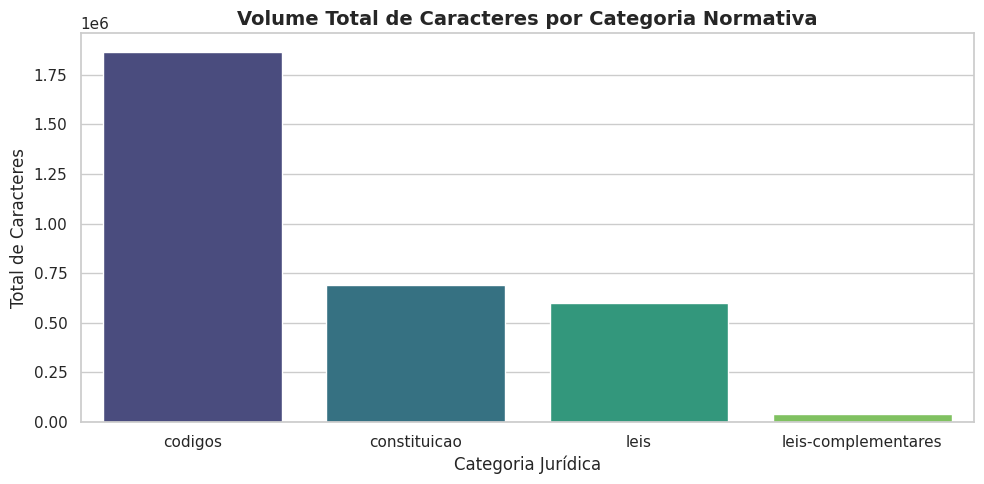

In [3]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df_cat_summary, x="categoria", y="caracteres_totais", hue="categoria", legend=False, palette="viridis")
plt.title("Volume Total de Caracteres por Categoria Normativa", fontsize=14, fontweight='bold')
plt.xlabel("Categoria Jurídica", fontsize=12)
plt.ylabel("Total de Caracteres", fontsize=12)
plt.tight_layout()
plt.show()

## 2. Análise de Dispositivos Legais (Granularidade Estrutural)
Mapeamos a densidade de **Artigos**, **Parágrafos (§)** e **Incisos (I, II, III)** em todo o corpus para entender a granularidade real dos textos legais.

In [4]:
# Um único padrão é utilizado na contagem e na segmentação dos artigos.
ARTICLE_PATTERN = re.compile(
    r'^[ \t]{0,3}(?:#{1,6}[ \t]+|\*\*)(?P<identificador>Art\.?[ \t]*\d+(?:[.，,]\d+)*(?:[º°])?(?:[-–—][A-Za-z]+)?)(?=[\s*.:]|$)',
    re.MULTILINE | re.IGNORECASE
)


def get_body_start(text):
    match = re.match(
        r'\A\ufeff?---[ \t]*\r?\n.*?\r?\n---[ \t]*(?:\r?\n|$)', text, re.DOTALL
    )
    return match.end() if match else 0


def build_articles_dataframe(df_corpus_input):
    records = []
    for _, row in df_corpus_input.iterrows():
        content = row['conteudo']
        body_start = get_body_start(content)
        matches = list(ARTICLE_PATTERN.finditer(content, body_start))
        for index, match in enumerate(matches):
            end = matches[index + 1].start() if index + 1 < len(matches) else len(content)
            records.append({
                'caminho_origem': row['caminho'],
                'cabecalho_artigo': match.group('identificador'),
                'ordem_artigo': index + 1,
                'posicao_inicio': match.start(),
                'posicao_fim': end,
                'texto': content[match.start():end],
                'caracteres': len(content[match.start():end].strip()),
                'tokens_estimados': len(content[match.start():end].strip()) / 4
            })
    columns = ['caminho_origem', 'cabecalho_artigo', 'ordem_artigo', 'posicao_inicio',
               'posicao_fim', 'texto', 'caracteres', 'tokens_estimados']
    return pd.DataFrame(records, columns=columns)


def count_legal_devices(text):
    body = text[get_body_start(text):]
    matches = list(ARTICLE_PATTERN.finditer(body))
    # Remove somente o marcador do artigo, preservando menções na mesma linha.
    without_markers = ARTICLE_PATTERN.sub('', body)
    return pd.Series({
        'artigos': len(matches),
        'mencoes_artigos': len(re.findall(r'\bArt\.?\s*\d+', without_markers, re.IGNORECASE)),
        'paragrafos': len(re.findall(r'§\s*\d+', body)),
        'incisos': len(re.findall(r'\b[IVXLCDM]+\s*[-–—)]', body))
    })


# Parágrafos e incisos são indicadores aproximados e podem incluir remissões.
df_corpus[['qtd_artigos', 'qtd_mencoes_artigos', 'qtd_paragrafos', 'qtd_incisos']] = df_corpus['conteudo'].apply(count_legal_devices)
df_dispositivos = df_corpus[
    ['nome_arquivo', 'caminho', 'qtd_artigos', 'qtd_mencoes_artigos', 'qtd_paragrafos', 'qtd_incisos']
].sort_values(by='qtd_artigos', ascending=False)
display(df_dispositivos.reset_index(drop=True).head(10))

,nome_arquivo,caminho,qtd_artigos,qtd_mencoes_artigos,qtd_paragrafos,qtd_incisos
0,codigo-civil-lei-10406-2002.md,codigos/codigo-civil-lei-10406-2002.md,2083,151,550,1243
1,codigo-de-processo-civil-lei-13105-2015.md,codigos/codigo-de-processo-civil-lei-13105-201...,1074,243,1507,1533
2,consolidacao-das-leis-do-trabalho-clt-del-5452...,codigos/consolidacao-das-leis-do-trabalho-clt-...,1016,193,950,595
3,constituicao-1988.md,constituicao/constituicao-1988.md,427,463,1378,1530
4,lei-8213-1991.md,leis/1991/lei-8213-1991.md,178,115,395,236
5,lei-8212-1991.md,leis/1991/lei-8212-1991.md,118,116,322,178
6,lei-8036-1990.md,leis/1990/lei-8036-1990.md,49,51,190,123
7,lcp-150-2015.md,leis-complementares/2015/lcp-150-2015.md,48,61,82,69
8,lei-7998-1990.md,leis/1990/lei-7998-1990.md,45,21,43,56
9,lei-14457-2022.md,leis/2022/lei-14457-2022.md,35,40,45,80


### Gráfico 2: Top Normas por Quantidade de Artigos

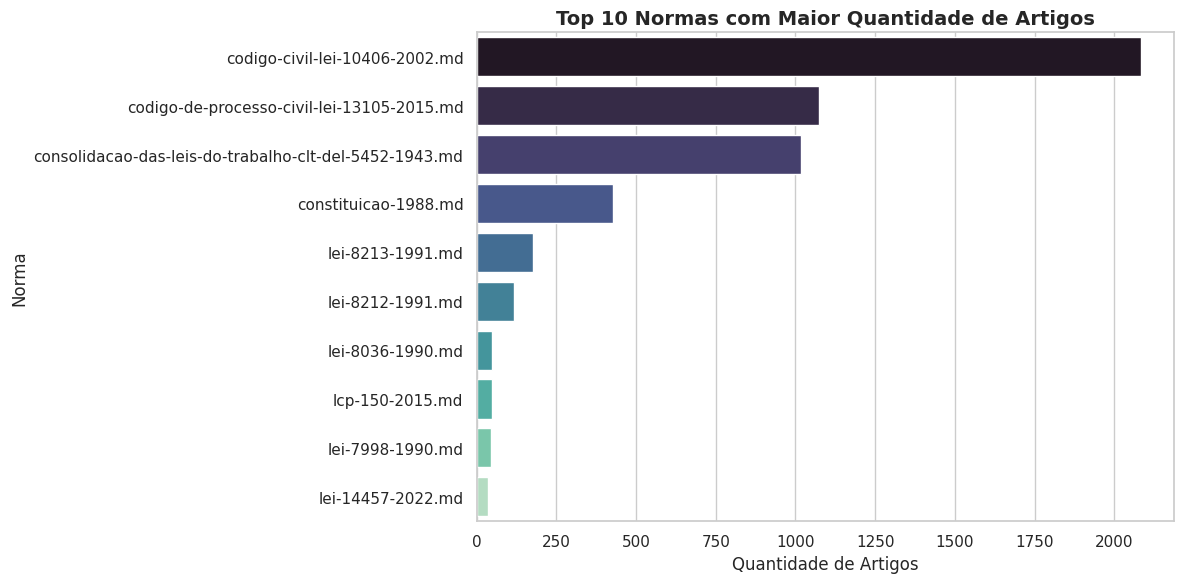

In [5]:
plt.figure(figsize=(12, 6))
top_artigos = df_dispositivos.sort_values(by="qtd_artigos", ascending=False).head(10)
sns.barplot(data=top_artigos, x="qtd_artigos", y="nome_arquivo", hue="nome_arquivo", legend=False, palette="mako")
plt.title("Top 10 Normas com Maior Quantidade de Artigos", fontsize=14, fontweight='bold')
plt.xlabel("Quantidade de Artigos", fontsize=12)
plt.ylabel("Norma", fontsize=12)
plt.tight_layout()
plt.show()

## 3. Distribuição de Tamanhos e Estimativa de Tokens por Artigo
Para definir a estratégia de *chunking* do RAG, precisamos analisar o tamanho médio dos blocos textuais. Calculamos a distribuição de caracteres e estimamos o número de tokens (considerando a proporção média de ~4 caracteres por token em modelos multilíngues/português).

In [6]:
def split_legal_articles(text):
    body_start = get_body_start(text)
    matches = list(ARTICLE_PATTERN.finditer(text, body_start))
    if not matches:
        return text[body_start:].strip(), []
    preambulo = text[body_start:matches[0].start()].strip()
    articles = []
    for index, match in enumerate(matches):
        end = matches[index + 1].start() if index + 1 < len(matches) else len(text)
        articles.append(text[match.start():end].strip())
    return preambulo, articles


def extract_article_lengths(text):
    _, articles = split_legal_articles(text)
    return [len(article) for article in articles]


df_artigos_detalhado = build_articles_dataframe(df_corpus)
if df_artigos_detalhado.empty:
    raise ValueError('Nenhum início de artigo reconhecido no corpus.')

df_lengths = df_artigos_detalhado[
    ['caminho_origem', 'cabecalho_artigo', 'ordem_artigo', 'caracteres', 'tokens_estimados']
].copy()
preambulo_records = []
for _, row in df_corpus.iterrows():
    preambulo, articles = split_legal_articles(row['conteudo'])
    preambulo_records.append({
        'nome_arquivo': row['nome_arquivo'], 'caminho': row['caminho'],
        'preambulo': preambulo, 'caracteres_preambulo': len(preambulo),
        'artigos_detectados': len(articles)
    })
df_preambulos = pd.DataFrame(preambulo_records)
assert len(df_lengths) == df_corpus['qtd_artigos'].sum()
print(f'• Blocos de artigos detectados: {len(df_lengths)}')
print(f"• Normas sem artigos reconhecidos: {(df_preambulos['artigos_detectados'] == 0).sum()}")
display(df_lengths[['caracteres', 'tokens_estimados']].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]))

• Blocos de artigos detectados: 5284
• Normas sem artigos reconhecidos: 0


,caracteres,tokens_estimados
count,5284.000000,5284.000000
mean,597.445307,149.361327
std,1113.616274,278.404069
min,21.000000,5.250000
25%,179.000000,44.750000
50%,299.000000,74.750000
75%,597.000000,149.250000
90%,1253.000000,313.250000
95%,1948.550000,487.137500
max,26547.000000,6636.750000


### Gráfico 3: Histograma de Distribuição de Tokens por Artigo

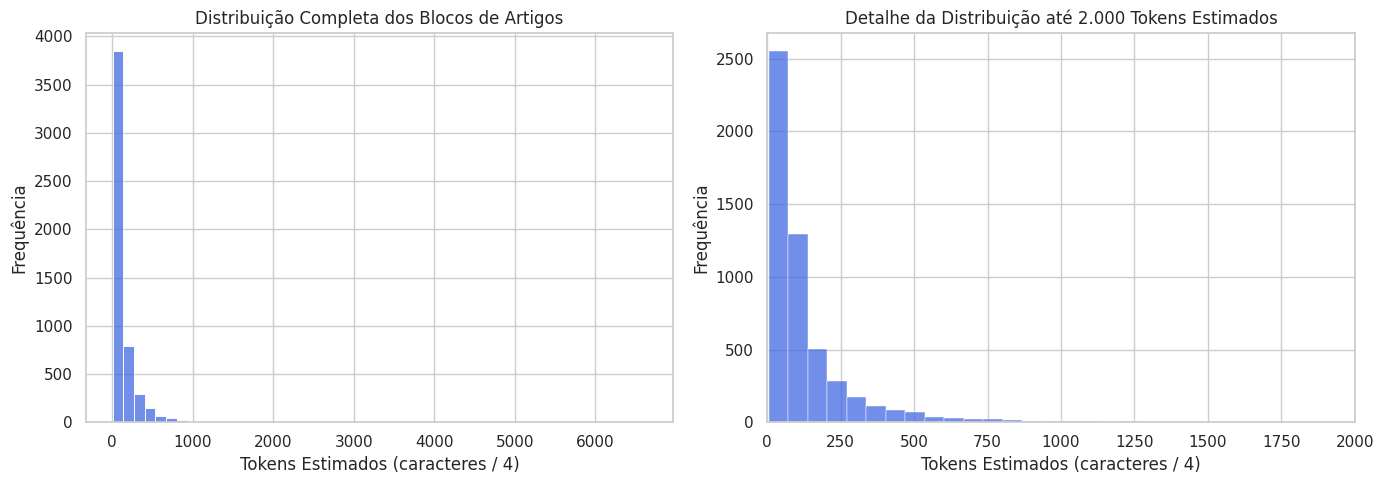

• Blocos acima do limite do gráfico ampliado: 22


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df_lengths, x='tokens_estimados', bins=50, color='royalblue', ax=axes[0])
axes[0].set_title('Distribuição Completa dos Blocos de Artigos')
axes[0].set_xlabel('Tokens Estimados (caracteres / 4)')
axes[0].set_ylabel('Frequência')
sns.histplot(data=df_lengths, x='tokens_estimados', bins=100, color='royalblue', ax=axes[1])
axes[1].set_xlim(0, 2000)
axes[1].set_title('Detalhe da Distribuição até 2.000 Tokens Estimados')
axes[1].set_xlabel('Tokens Estimados (caracteres / 4)')
axes[1].set_ylabel('Frequência')
plt.tight_layout()
plt.show()
print(f"• Blocos acima do limite do gráfico ampliado: {(df_lengths['tokens_estimados'] > 2000).sum()}")

## 4. Presença de Notas, Referências Cruzadas e Alterações
Identificamos a incidência de menções a notas de rodapé, expressões como *(Vide...)*, *(Redação dada pela Lei nº...)* ou remissões temporais, que afetam a recuperação semântica no RAG.

In [8]:
def audit_references_and_notes(text):
    vide_count = len(re.findall(r'\(Vide[^)]+\)', text, re.IGNORECASE))
    redacao_count = len(re.findall(r'\(Redação dada', text, re.IGNORECASE))
    revogado_count = len(re.findall(r'\(Revogado', text, re.IGNORECASE))
    
    return pd.Series([vide_count, redacao_count, revogado_count], index=['vide', 'redacao_dada', 'revogado'])

df_corpus[['qtd_vide', 'qtd_redacao', 'qtd_revogado']] = df_corpus['conteudo'].apply(audit_references_and_notes)

summary_ref = df_corpus[['nome_arquivo', 'qtd_vide', 'qtd_redacao', 'qtd_revogado']].sum(numeric_only=True)
print("🔍 Incidência de Marcas Legislativas no Corpus:")
print(summary_ref)

🔍 Incidência de Marcas Legislativas no Corpus:
qtd_vide         533
qtd_redacao     1909
qtd_revogado     550
dtype: int64


## 5. Orientações para a Estratégia de Chunking (Próxima Etapa)
As orientações abaixo são calculadas a partir dos blocos de artigos detectados neste notebook. A estimativa de tokens utiliza caracteres / 4 e deverá ser conferida com o tokenizador do modelo escolhido antes dos experimentos de chunking.

As contagens representam cabeçalhos detectados, não necessariamente dispositivos jurídicos únicos. Normas sem cabeçalhos reconhecidos não participam da distribuição por artigo.

Notas e referências devem permanecer associadas aos dispositivos correspondentes para preservar o contexto. Essa associação, isoladamente, não comprova a vigência nem garante a correção jurídica das respostas.

In [9]:
# Calcula as orientações com base nos resultados efetivamente observados.
LIMIAR_TOKENS = 500
if df_lengths.empty:
    raise ValueError("Não há blocos de artigos para gerar as orientações de chunking.")

total_artigos = len(df_lengths)
abaixo_limiar = int((df_lengths['tokens_estimados'] < LIMIAR_TOKENS).sum())
acima_ou_igual = total_artigos - abaixo_limiar
proporcao_abaixo = abaixo_limiar / total_artigos * 100
p95_tokens = df_lengths['tokens_estimados'].quantile(0.95)
max_tokens = df_lengths['tokens_estimados'].max()
sem_cabecalhos = int((df_preambulos['artigos_detectados'] == 0).sum())

print("📊 ORIENTAÇÕES PARA OS EXPERIMENTOS DE CHUNKING")
print(f"• Blocos de artigos analisados: {total_artigos}")
print(f"• Blocos com menos de {LIMIAR_TOKENS} tokens estimados: {abaixo_limiar} ({proporcao_abaixo:.2f}%)")
print(f"• Blocos com {LIMIAR_TOKENS} tokens estimados ou mais: {acima_ou_igual}")
print(f"• Percentil 95: {p95_tokens:.2f} tokens estimados")
print(f"• Maior bloco: {max_tokens:.2f} tokens estimados")
print(f"• Normas sem cabeçalhos reconhecidos, fora da distribuição: {sem_cabecalhos}")

if proporcao_abaixo > 50:
    print("• A maioria dos blocos ficou abaixo do limiar exploratório. Testar artigos completos como uma das estratégias de chunking.")
else:
    print("• Pelo menos metade dos blocos atingiu ou ultrapassou o limiar exploratório. Priorizar também experimentos de subdivisão por parágrafos.")

if acima_ou_igual > 0:
    print("• Inspecionar os blocos maiores e comparar a preservação do artigo completo com a subdivisão por parágrafos.")

print("• O limiar exploratório não representa a janela de contexto do modelo nem determina, sozinho, o tamanho ideal dos chunks.")

📊 ORIENTAÇÕES PARA OS EXPERIMENTOS DE CHUNKING
• Blocos de artigos analisados: 5284
• Blocos com menos de 500 tokens estimados: 5031 (95.21%)
• Blocos com 500 tokens estimados ou mais: 253
• Percentil 95: 487.14 tokens estimados
• Maior bloco: 6636.75 tokens estimados
• Normas sem cabeçalhos reconhecidos, fora da distribuição: 0
• A maioria dos blocos ficou abaixo do limiar exploratório. Testar artigos completos como uma das estratégias de chunking.
• Inspecionar os blocos maiores e comparar a preservação do artigo completo com a subdivisão por parágrafos.
• O limiar exploratório não representa a janela de contexto do modelo nem determina, sozinho, o tamanho ideal dos chunks.


## Inspecionando Normas sem Padrão de Artigos Reconhecidos
Algumas normas ou arquivos auxiliares podem não seguir o formato clássico `Art. X`. Nesta etapa, filtramos e inspecionamos os arquivos onde a contagem de artigos foi igual a zero, avaliando se possuem outra formatação estrutural (ex: cláusulas, itens, resoluções) ou se tratam de textos informativos que precisam de tratamento diferenciado no RAG.

In [10]:
normas_sem_artigos = df_corpus[df_corpus['qtd_artigos'] == 0]
print(f'• Normas sem início de artigo reconhecido: {len(normas_sem_artigos)}')
for _, row in normas_sem_artigos.iterrows():
    body = row['conteudo'][get_body_start(row['conteudo']):]
    print(f"\n📄 Arquivo: {row['caminho']}")
    print('\n'.join(body.splitlines()[:20]))
    print('• Revisar a formatação do corpo; a ausência de correspondência não comprova ausência de artigos.')

• Normas sem início de artigo reconhecido: 0


## Tabela Detalhada por Bloco de Artigo
Nesta etapa, decompomos cada norma em seus respectivos artigos, registrando o caminho de origem, o cabeçalho identificador, a posição exata (caractere inicial) no texto, o volume de caracteres e a estimativa de tokens. Essa granularidade tabular permite isolar rapidamente *outliers* (artigos excessivamente longos ou blocos corrompidos) que exigem revisão manual ou tratamento especial no *chunking*.

In [11]:
# A tabela usa a mesma segmentação empregada nas estatísticas e nos gráficos.
print(f'• Total de blocos de artigos: {len(df_artigos_detalhado)}')
columns = ['caminho_origem', 'cabecalho_artigo', 'posicao_inicio', 'posicao_fim', 'caracteres', 'tokens_estimados']
print('🔍 Maiores blocos para revisão:')
display(df_artigos_detalhado.sort_values('caracteres', ascending=False)[columns].head(10))
print('🔍 Menores blocos para revisão:')
display(df_artigos_detalhado.sort_values('caracteres')[columns].head(10))
for label, sample in [
    ('Maior bloco', df_artigos_detalhado.nlargest(1, 'caracteres')),
    ('Menor bloco', df_artigos_detalhado.nsmallest(1, 'caracteres'))
]:
    for _, row in sample.iterrows():
        print(f"\n{label}: {row['caminho_origem']} | {row['cabecalho_artigo']}")
        print(row['texto'][:1200])
        print('--- Final do bloco ---')
        print(row['texto'][-400:])

# Títulos e anexos podem estar incluídos no bloco anterior; apenas sinalizamos.
df_excecoes = df_artigos_detalhado[
    df_artigos_detalhado['texto'].str.contains(
        r'(?im)^[ \t]*(?:#{1,6}\s+|\*\*)?(?:T[ÍI]TULO|CAP[ÍI]TULO|SE[ÇC][ÃA]O|ANEXO)\b', regex=True
    )
].copy()
df_excecoes['motivo_revisao'] = 'Possível título estrutural ou anexo dentro do bloco; revisar os limites.'
print(f'• Blocos com possíveis títulos ou anexos internos: {len(df_excecoes)}')

• Total de blocos de artigos: 5284
🔍 Maiores blocos para revisão:


,caminho_origem,cabecalho_artigo,posicao_inicio,posicao_fim,caracteres,tokens_estimados
4172,codigos/consolidacao-das-leis-do-trabalho-clt-...,Art. 922,603712,630260,26547,6636.75
4273,constituicao/constituicao-1988.md,Art. 100,177849,197263,19412,4853.00
4805,leis/1990/lei-8036-1990.md,Art. 20,43976,60130,16152,4038.00
4839,leis/1991/lei-8212-1991.md,Art. 12,6299,21937,15636,3909.00
4956,leis/1991/lei-8213-1991.md,Art. 11,7866,23130,15262,3815.50
4555,constituicao/constituicao-1988.md,Art. 97,595000,609369,14367,3591.75
2082,codigos/codigo-civil-lei-10406-2002.md,Art. 2.046,633714,647997,14282,3570.50
4177,constituicao/constituicao-1988.md,Art. 5º,3470,17582,14110,3527.50
4338,constituicao/constituicao-1988.md,Art. 156-A,304345,317968,13621,3405.25
4210,constituicao/constituicao-1988.md,Art. 37,75349,88385,13034,3258.50


🔍 Menores blocos para revisão:


,caminho_origem,cabecalho_artigo,posicao_inicio,posicao_fim,caracteres,tokens_estimados
5192,leis/2022/lei-14442-2022.md,Art. 7º,11083,11106,21,5.25
5156,leis/2006/lei-11419-2006.md,Art. 17,13997,14021,22,5.50
2117,codigos/codigo-de-processo-civil-lei-13105-201...,Art. 35,13247,13271,22,5.50
5160,leis/2006/lei-11419-2006.md,Art. 21,19415,19439,22,5.50
4757,leis/1990/lei-7998-1990.md,Art. 14,20564,20588,22,5.50
4755,leis/1990/lei-7998-1990.md,Art. 12,20516,20540,22,5.50
4772,leis/1990/lei-7998-1990.md,Art. 26,27829,27853,22,5.50
4756,leis/1990/lei-7998-1990.md,Art. 13,20540,20564,22,5.50
3139,codigos/codigo-de-processo-civil-lei-13105-201...,Art. 1.055,577195,577222,25,6.25
4874,leis/1991/lei-8212-1991.md,Art. 40,91630,91657,25,6.25



Maior bloco: codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md | Art. 922
##### Art. 922

O disposto no art. 301 regerá somente as relações de empregos iniciadas depois da vigência desta Consolidação. (Incluído pelo Decreto-lei nº 6.353, de 20.3.1944)

## ANEXO — Quadro a que se refere o art. 577 da Consolidação das Leis do Trabalho

<table>
<tr><td>CONFEDERAÇÃO NACIONAL DA INDÚSTRIA</td><td>CONFEDERAÇÃO NACIONAL DOS TRABALHADORES NA INDÚSTRIA</td></tr>
<tr><td>1º GRUPO - Indústria da alimentação Atividades ou categorias econômicas</td><td>1º GRUPO - Trabalhadores na indústria de alimentação Categorias profissionais</td></tr>
<tr><td>Indústria do trigo Indústria do milho e da soja Indústria da mandioca</td><td>Trabalhadores na indústria do trigo, milho e mandioca</td></tr>
<tr><td>Indústria do arroz</td><td>Trabalhadores na indústria do arroz</td></tr>
<tr><td>Indústria do açúcar Indústria do açúcar de engenho</td><td>Trabalhadores na indústria do açúcar</td></tr>
<tr><td

## Mapeamento de Formatos de Dispositivos (Regras para o Parser)
Os textos legais brasileiros possuem uma microestrutura altamente padronizada, mas repleta de variações (sufixos em artigos, parágrafo único vs. parágrafos numerados, incisos em romanos e alíneas). Nesta etapa, varremos o corpus utilizando expressões regulares (Regex) para identificar exemplos reais dessas variações, fornecendo a base empírica necessária para projetar as regras robustas do *parser* de extração.

In [12]:
def audit_device_formats(df_corpus_input):
    patterns = {
        'Artigos com sufixos': r'\bArt\.?\s*\d+[-–—][A-Za-z]+\b',
        'Parágrafo único': r'Parágrafo\s+único',
        'Parágrafos numerados': r'§\s*\d+[º°]?',
        'Incisos (candidatos)': r'^[ \t]*(?:\*\*)?[IVXLCDM]+\s*[-–—)]',
        'Alíneas (candidatas)': r'^[ \t]*(?:\*\*)?[a-z]\)'
    }
    summary = []
    examples = []
    for name, pattern in patterns.items():
        count = 0
        for _, row in df_corpus_input.iterrows():
            text = row['conteudo']
            for match in re.finditer(pattern, text, re.MULTILINE):
                if match.start() < get_body_start(text):
                    continue
                count += 1
                examples.append({
                    'tipo_dispositivo': name, 'caminho_origem': row['caminho'],
                    'posicao_inicio': match.start(), 'ocorrencia': match.group(0).strip(),
                    'contexto': text[max(0, match.start()-40):match.end()+120]
                })
        summary.append({'tipo_dispositivo': name, 'padrao_regex_utilizado': pattern,
                        'ocorrencias_totais': count})
    return pd.DataFrame(summary), pd.DataFrame(examples, columns=[
        'tipo_dispositivo', 'caminho_origem', 'posicao_inicio', 'ocorrencia', 'contexto'
    ])

df_formatos, df_exemplos_formatos = audit_device_formats(df_corpus.sort_values('caminho'))
display(df_formatos)
display(df_exemplos_formatos.groupby('tipo_dispositivo', sort=True).head(5))

,tipo_dispositivo,padrao_regex_utilizado,ocorrencias_totais
0,Artigos com sufixos,\bArt\.?\s*\d+[-–—][A-Za-z]+\b,204
1,Parágrafo único,Parágrafo\s+único,1041
2,Parágrafos numerados,§\s*\d+[º°]?,5706
3,Incisos (candidatos),^[ \t]*(?:\*\*)?[IVXLCDM]+\s*[-–—)],4725
4,Alíneas (candidatas),^[ \t]*(?:\*\*)?[a-z]\),1285


,tipo_dispositivo,caminho_origem,posicao_inicio,ocorrencia,contexto
0,Artigos com sufixos,codigos/codigo-civil-lei-10406-2002.md,16703,Art. 48-A,"de erro, dolo, simulação ou fraude.\n\n**Art...."
1,Artigos com sufixos,codigos/codigo-civil-lei-10406-2002.md,17221,Art. 49-A,mear-lhe-á administrador provisório.\n\n**Art....
2,Artigos com sufixos,codigos/codigo-civil-lei-10406-2002.md,62181,Art. 206-A,do vencido o que despendeu em juízo.\n\n**Art....
3,Artigos com sufixos,codigos/codigo-civil-lei-10406-2002.md,111733,Art. 421-A,"ncluído pela Lei nº 13.874, de 2019)\n\n**Art...."
4,Artigos com sufixos,codigos/codigo-civil-lei-10406-2002.md,204312,Art. 819-A,não admite interpretação extensiva.\n\n**Art....
204,Parágrafo único,codigos/codigo-civil-lei-10406-2002.md,2013,Parágrafo único,de 2015) (Vigência)\n\nIV - os pródigos.\n\nPa...
205,Parágrafo único,codigos/codigo-civil-lei-10406-2002.md,2285,Parágrafo único,rática de todos os atos da vida civil.\n\nPará...
206,Parágrafo único,codigos/codigo-civil-lei-10406-2002.md,3319,Parágrafo único,té dois anos após o término da guerra.\n\nPará...
207,Parágrafo único,codigos/codigo-civil-lei-10406-2002.md,4706,Parágrafo único,zo de outras sanções previstas em lei.\n\nPará...
208,Parágrafo único,codigos/codigo-civil-lei-10406-2002.md,5084,Parágrafo único,"ísica, ou contrariar os bons costumes.\n\nPará..."


## Detalhamento de Notas, Referências e Candidatos a Ruído
Registramos exemplos localizáveis de marcas legislativas, links e possíveis artefatos. Aspas, links e avisos de alteração não são classificados automaticamente como ruído. Destinos de links e marcas jurídicas devem ser preservados para revisão na etapa 03. Nenhum conteúdo é removido nesta EDA.

In [13]:
def audit_textual_noise_and_notes(df_corpus_input):
    patterns = {
        'Remissão Vide': (r'\bVide\b', 'Preservar referência e contexto'),
        'Histórico de redação': (r'Redação\s+dada', 'Preservar histórico e vínculo com o dispositivo'),
        'Marca de revogação': (r'\bRevogad[oa]s?\b', 'Preservar para revisão jurídica'),
        'Link Markdown': (r'\[[^\]]+\]\(([^)]+)\)', 'Preservar texto e destino do link'),
        'Nota Markdown': (r'\[\^[^\]]+\]', 'Preservar vínculo entre chamada e nota'),
        'Quebra de página': (r'\f', 'Candidato a remoção; confirmar por inspeção')
    }
    records = []
    for _, row in df_corpus_input.sort_values('caminho').iterrows():
        text = row['conteudo']
        body_start = get_body_start(text)
        for name, (pattern, action) in patterns.items():
            for match in re.finditer(pattern, text, re.IGNORECASE):
                if match.start() < body_start:
                    continue
                records.append({
                    'caminho_origem': row['caminho'], 'tipo_elemento': name,
                    'posicao_inicio': match.start(), 'ocorrencia': match.group(0),
                    'destino_link': match.group(1) if name == 'Link Markdown' else '',
                    'contexto': text[max(body_start, match.start()-80):match.end()+160],
                    'acao_proposta': action
                })
    return pd.DataFrame(records, columns=['caminho_origem', 'tipo_elemento',
        'posicao_inicio', 'ocorrencia', 'destino_link', 'contexto', 'acao_proposta'])

df_notas_exemplos = audit_textual_noise_and_notes(df_corpus)
df_ruidos_audit = df_notas_exemplos.groupby('tipo_elemento').size().reset_index(name='ocorrencias')
display(df_ruidos_audit)
display(df_notas_exemplos.groupby('tipo_elemento', sort=True).head(3))

,tipo_elemento,ocorrencias
0,Histórico de redação,1914
1,Marca de revogação,670
2,Remissão Vide,551


,caminho_origem,tipo_elemento,posicao_inicio,ocorrencia,destino_link,contexto,acao_proposta
0,codigos/codigo-civil-lei-10406-2002.md,Remissão Vide,634,Vide,,go Civil.*\n\n> ÍNDICE\n>\n> Lei de Introdução...,Preservar referência e contexto
1,codigos/codigo-civil-lei-10406-2002.md,Remissão Vide,667,Vide,,ntrodução às normas do Direito Brasileiro\n>\n...,Preservar referência e contexto
2,codigos/codigo-civil-lei-10406-2002.md,Remissão Vide,6438,Vide,,"onra, a boa fama ou a respeitabilidade, ou se ...",Preservar referência e contexto
17,codigos/codigo-civil-lei-10406-2002.md,Histórico de redação,1277,Redação dada,,exercer pessoalmente os atos da vida civil os...,Preservar histórico e vínculo com o dispositivo
18,codigos/codigo-civil-lei-10406-2002.md,Histórico de redação,1349,Redação dada,,"anos. (Redação dada pela Lei nº 13.146, de 20...",Preservar histórico e vínculo com o dispositivo
19,codigos/codigo-civil-lei-10406-2002.md,Histórico de redação,1422,Redação dada,,"do) ; (Redação dada pela Lei nº 13.146, de 201...",Preservar histórico e vínculo com o dispositivo
117,codigos/codigo-civil-lei-10406-2002.md,Marca de revogação,1336,Revogado,,6 (dezesseis) anos. (Redação dada pela Lei nº ...,Preservar para revisão jurídica
118,codigos/codigo-civil-lei-10406-2002.md,Marca de revogação,1409,Revogado,,\n\nI - (Revogado) ; (Redação dada pela Lei nº...,Preservar para revisão jurídica
119,codigos/codigo-civil-lei-10406-2002.md,Marca de revogação,1483,Revogado,,II - (Revogado) ; (Redação dada pela Lei nº 13...,Preservar para revisão jurídica


## Conferência de Correspondência entre Auditoria e EDA
Comparamos caminhos relativos normalizados e hashes SHA-256 dos bytes originais. A igualdade dos nomes, isoladamente, não confirma a integridade. A conferência registra divergências e não substitui a avaliação das pendências da auditoria.

In [14]:
import hashlib

audit_report_path = PROJECT_ROOT / 'reports/legislacao/auditoria/auditoria_legislacao_resumo.csv'
if not audit_report_path.is_file():
    raise FileNotFoundError(f'Relatório de auditoria não encontrado: {audit_report_path}')

df_audit = pd.read_csv(audit_report_path, dtype=str)
required = {'caminho_relativo', 'sha256'}
if not required.issubset(df_audit.columns):
    raise ValueError('Relatório sem caminhos ou SHA-256. Execute novamente a auditoria atualizada.')

df_audit['caminho_relativo'] = df_audit['caminho_relativo'].str.replace('\\', '/', regex=False)
current_records = []
for _, row in df_corpus.iterrows():
    current_records.append({
        'caminho_relativo': row['caminho'].replace('\\', '/'),
        'sha256_eda': hashlib.sha256((RAW_DIR / row['caminho']).read_bytes()).hexdigest()
    })
df_rastreabilidade = df_audit[['caminho_relativo', 'sha256']].merge(
    pd.DataFrame(current_records), on='caminho_relativo', how='outer',
    indicator=True, validate='one_to_one'
)
df_rastreabilidade['status_correspondencia'] = df_rastreabilidade.apply(
    lambda row: 'Ausente na EDA' if row['_merge'] == 'left_only' else
                'Não auditado' if row['_merge'] == 'right_only' else
                'OK' if row['sha256'] == row['sha256_eda'] else 'Hash divergente', axis=1
)
display(df_rastreabilidade)
lineage_ok = bool(df_rastreabilidade['status_correspondencia'].eq('OK').all())
print(f'• Correspondência de caminhos e conteúdo confirmada: {lineage_ok}')

,caminho_relativo,sha256,sha256_eda,_merge,status_correspondencia
0,codigos/codigo-civil-lei-10406-2002.md,02f30e533422f8aed9566953b7a731642b3d2293de3c37...,02f30e533422f8aed9566953b7a731642b3d2293de3c37...,both,OK
1,codigos/codigo-de-processo-civil-lei-13105-201...,39006ac91e7e93548cbdcbf167d69746f6b4d0ca45d5d8...,39006ac91e7e93548cbdcbf167d69746f6b4d0ca45d5d8...,both,OK
2,codigos/consolidacao-das-leis-do-trabalho-clt-...,59106e488eed2be8ff895024b11d747519ebf90320c7f1...,59106e488eed2be8ff895024b11d747519ebf90320c7f1...,both,OK
3,constituicao/constituicao-1988.md,1c9a24309a4e7dead57dc955e831219f4d438678744ea8...,1c9a24309a4e7dead57dc955e831219f4d438678744ea8...,both,OK
4,leis-complementares/2015/lcp-150-2015.md,a857c64a3fb78c7f6b02aad2506d792e2bb58592500c64...,a857c64a3fb78c7f6b02aad2506d792e2bb58592500c64...,both,OK
5,leis/1949/lei-605-1949.md,abb1abb11c4cd2af8c48fe7c69a58c2e8285e77190f930...,abb1abb11c4cd2af8c48fe7c69a58c2e8285e77190f930...,both,OK
6,leis/1962/lei-4090-1962.md,590e7a949b5f702b9e893ea039cf394f4a2e20568b4e02...,590e7a949b5f702b9e893ea039cf394f4a2e20568b4e02...,both,OK
7,leis/1965/lei-4749-1965.md,a9370019e798cb5a3804946bd49b7af8ae33e8dd54e82b...,a9370019e798cb5a3804946bd49b7af8ae33e8dd54e82b...,both,OK
8,leis/1970/lei-5584-1970.md,021eb4818e2a3af2058757870aaa63585d1eea4f35f032...,021eb4818e2a3af2058757870aaa63585d1eea4f35f032...,both,OK
9,leis/1973/lei-5889-1973.md,a490a1fc3392bfe0643e58981205a244d43fac7cb2934e...,a490a1fc3392bfe0643e58981205a244d43fac7cb2934e...,both,OK


• Correspondência de caminhos e conteúdo confirmada: True


## Exportação das Evidências para a Etapa 03
Exportamos tabelas exploratórias e exceções, sem modificar os arquivos originais. As posições são índices de caracteres no texto carregado em UTF-8, com quebras de linha normalizadas pelo Python; não são posições em bytes. Os blocos ainda podem conter títulos e anexos e deverão ter seus limites revisados na estruturação.

In [15]:
import json
from datetime import datetime, timezone

EDA_REPORT_DIR = PROJECT_ROOT / 'reports/legislacao/eda'
EDA_REPORT_DIR.mkdir(parents=True, exist_ok=True)
reports = {
    'eda_normas': df_corpus.drop(columns='conteudo'),
    'eda_artigos': df_artigos_detalhado,
    'eda_preambulos': df_preambulos,
    'eda_excecoes_blocos': df_excecoes,
    'eda_normas_sem_artigos': normas_sem_artigos.drop(columns='conteudo'),
    'eda_formatos': df_formatos,
    'eda_exemplos_formatos': df_exemplos_formatos,
    'eda_notas_referencias': df_notas_exemplos,
    'eda_rastreabilidade': df_rastreabilidade.drop(columns='_merge')
}
for name, dataframe in reports.items():
    dataframe.to_csv(EDA_REPORT_DIR / f'{name}.csv', index=False, encoding='utf-8')
    dataframe.to_json(EDA_REPORT_DIR / f'{name}.json', orient='records', force_ascii=False, indent=4)

resumo = {
    'executado_em_utc': datetime.now(timezone.utc).isoformat(),
    'normas': len(df_corpus), 'blocos_artigos': len(df_artigos_detalhado),
    'normas_sem_artigos': len(normas_sem_artigos),
    'percentual_abaixo_500_tokens_estimados': proporcao_abaixo,
    'estimativa_tokens': 'caracteres / 4; sem tokenizador de modelo',
    'correspondencia_auditoria_confirmada': lineage_ok,
    'regras_propostas_etapa_03': [
        'Preservar origem, hash e posições dos dispositivos.',
        'Revisar títulos e anexos nos limites dos blocos antes de estruturar.',
        'Preservar notas, remissões, destinos de links e histórico de alterações.',
        'Remover apenas ruídos confirmados e registrar cada transformação.',
        'Validar parágrafos, incisos e alíneas com os exemplos coletados.'
    ]
}
with open(EDA_REPORT_DIR / 'eda_resumo.json', 'w', encoding='utf-8') as f:
    json.dump(resumo, f, ensure_ascii=False, indent=4)
print(f'• Evidências exportadas em: {EDA_REPORT_DIR}')
if not lineage_ok:
    print('⚠️ Resolver as divergências de rastreabilidade antes de usar a base no notebook 03.')

• Evidências exportadas em: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\legislacao\eda
